# **Estimación de la frecuencia cardiaca a partir de señales ECG contaminadas**
## **Tratamiento de Señales Discretas 2026-2 · Grupo 08 · Versión definitiva**

**Idea base:** uso el algoritmo de **Pan y Tompkins (1985)**. Limpio la señal con dos filtros, resalto los complejos QRS, detecto los picos R y con el tiempo entre picos (intervalo RR) calculo
$$FC = \frac{60}{\overline{RR}}\ \text{[lpm]}$$

**Cómo está organizado**
- **Parte A – Funciones:** una función corta por cada operación.
- **Parte B – Elegir las señales:** **lo único que hay que cambiar.**
- **Parte C – Paso a paso:** cada paso procesa **todas** las señales elegidas y muestra una gráfica por señal.
- **Parte D – Archivo de resultados:** procesa las 48 señales y guarda `resultados_g08.csv`.

# **PARTE A – Funciones**
## **A.1 Librerías y datos**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import iirnotch, butter, filtfilt, find_peaks

CARPETA = "data"      # aquí están los archivos senal_XX.csv y el LEEME.txt
plt.rcParams["figure.dpi"] = 72

## **A.2 Leer una señal**
Leo el archivo (columnas `tiempo_s` y `ecg_mV`) y calculo la frecuencia de muestreo con el paso de tiempo: $f_s = 1/\Delta t$. Así el código sirve para **cualquier** $f_s$.

Puedo darle el **número** de la señal (`7` → `data/senal_07.csv`) o el **nombre del archivo** si el profesor trae uno nuevo (`"prueba.csv"`).

*Referencia:* muestreo periódico $x[n] = x(nT)$, $f_s = 1/T$ (Oppenheim y Schafer, 2010, Sec. 4.1).

In [2]:
def leer_senal(senal):
    # Si me dan un número, armo el nombre del archivo; si me dan un nombre, lo uso tal cual
    if type(senal) == int:
        archivo = CARPETA + "/senal_" + str(senal).zfill(2) + ".csv"
    else:
        archivo = CARPETA + "/" + senal
    datos = pd.read_csv(archivo)
    t = datos["tiempo_s"].values
    x = datos["ecg_mV"].values
    fs = round(1 / (t[1] - t[0]))      # calculo fs con el paso de tiempo
    return t, x, fs

## **A.3 Leer el LEEME**
Leo las líneas del `LEEME.txt` del tipo `senal_14: 90 Hz (2700 muestras)` y guardo la $f_s$ que declara cada señal en un diccionario `{14: 90, ...}`. Sirve para comprobar que la $f_s$ que calculé es la correcta.

In [3]:
def leer_leeme():
    fs_leeme = {}
    for linea in open(CARPETA + "/LEEME.txt", encoding="utf-8", errors="ignore"):
        linea = linea.strip()                                   # le quito los espacios del inicio
        if linea.startswith("senal_") and "Hz" in linea:
            nombre, resto = linea.split(":")
            numero = int(nombre.replace("senal_", ""))
            fs_leeme[numero] = float(resto.split("Hz")[0])    # me quedo con el número antes de "Hz"
    return fs_leeme

## **A.4 Clasificar por frecuencia de muestreo**
La frecuencia más alta que puedo ver es $f_s/2$ (Nyquist). Con eso pongo cada señal en un grupo:
- **Grupo A:** $60 < f_s/2$ → la red de 60 Hz se ve en 60 Hz (y 120 Hz si cabe).
- **Grupo B:** $60 \ge f_s/2$ → la red se **dobla** (aliasing) y aparece en $f_a = |f_0 - k f_s|$, con $k$ el entero más cercano a $f_0/f_s$. Con $f_s = 90$ Hz: $|60 - 90| = 30$ Hz.

La función devuelve el grupo y **dónde poner el notch**. Es la única diferencia entre grupos; todo lo demás está en Hz y segundos y vale para cualquier $f_s$.

*Referencias:* teorema de Nyquist (Oppenheim y Schafer, 2010, Sec. 4.2); frecuencia alias (Proakis y Manolakis, 2007, Sec. 1.4).

In [4]:
def clasificar(fs):
    if 60 < fs / 2:
        grupo = "A"          # la red cabe bajo Nyquist
    else:
        grupo = "B"          # la red sufre aliasing
    notch = []
    for f0 in [60, 120, 180]:                  # la red y sus armónicos
        k = round(f0 / fs)
        fa = abs(f0 - k * fs)                  # frecuencia donde aparece de verdad
        if 1 < fa < fs / 2 - 1 and fa not in notch:
            notch.append(fa)                   # la guardo si no está en 0 Hz ni en Nyquist
    return grupo, notch

## **A.5 Espectro (FFT)**
Calculo la FFT con ventana de Hann para ver en qué frecuencias está el ruido.

*Referencia:* DFT y FFT (Oppenheim y Schafer, 2010, Cap. 8 y 9).

In [5]:
def espectro(x, fs):
    ventana = np.hanning(len(x))
    X = np.fft.rfft((x - np.mean(x)) * ventana)
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return f, 2 * np.abs(X) / np.sum(ventana)     # normalizo para leer la amplitud en mV

## **A.6 Filtros**
- **Notch** (Q = 30): quita solo la red, en la frecuencia que dio `clasificar`.
- **Pasa-banda Butterworth 5–15 Hz** (orden 2): deja la banda del QRS y quita la deriva y el ruido muscular.

Los dos se aplican con `filtfilt` (adelante y atrás), así los picos R no se corren.

*Referencias:* notch (Proakis y Manolakis, 2007, Sec. 5.4); Butterworth (Oppenheim y Schafer, 2010, Cap. 7); banda 5–15 Hz (Pan y Tompkins, 1985, secc. *Bandpass Filter*, p. 232).

In [6]:
def filtro_notch(x, fs, notch):
    y = x - np.mean(x)
    for f0 in notch:
        b, a = iirnotch(f0, 30, fs)
        y = filtfilt(b, a, y)
    return y


def filtro_pasa_banda(x, fs):
    b, a = butter(2, [5 / (fs / 2), 15 / (fs / 2)], btype="band")
    return filtfilt(b, a, x)

## **A.7 Transformación de Pan y Tompkins**
1. **Derivada:** resalta las pendientes del QRS.
2. **Cuadrado:** todo queda positivo (sirve aunque el QRS esté invertido).
3. **Integración de 150 ms:** una "joroba" por latido.

*Referencia:* Pan y Tompkins (1985), secc. *Derivative* (pp. 232–233), *Squaring Function* y *Moving-Window Integration* (p. 233).

In [7]:
def pan_tompkins(x_banda, fs):
    derivada = np.gradient(x_banda) * fs
    cuadrado = derivada ** 2
    ancho = int(round(0.150 * fs))                    # 150 ms en muestras
    return np.convolve(cuadrado, np.ones(ancho) / ancho, mode="same")

## **A.8 Detectar los picos R (umbral adaptativo)**
- Busco las jorobas separadas al menos **200 ms** (periodo refractario).
- Llevo un nivel de **señal** y uno de **ruido**; el umbral es $\text{ruido} + 0.25(\text{señal} - \text{ruido})$ y se actualiza con cada joroba.
- Si pasa más de **1.66 veces el RR promedio** sin latido, busco el que se me escapó con la mitad del umbral.

*Referencia:* Pan y Tompkins (1985), secc. *Adjusting the Thresholds* (pp. 233–234) y *Algorithm Overview* (p. 231), búsqueda del 166 % (p. 234).

In [8]:
def detectar_picos(integrada, fs):
    candidatos, _ = find_peaks(integrada, distance=int(0.200 * fs))   # jorobas a más de 200 ms
    inicio = integrada[: int(2 * fs)]               # con los 2 primeros segundos inicio los niveles
    senal = 0.25 * np.max(inicio)
    ruido = 0.5 * np.mean(inicio)
    umbral = ruido + 0.25 * (senal - ruido)
    picos = []
    for p in candidatos:
        if integrada[p] > umbral:
            picos.append(p)                                   # es un latido
            senal = 0.125 * integrada[p] + 0.875 * senal
        else:
            ruido = 0.125 * integrada[p] + 0.875 * ruido      # es ruido
        umbral = ruido + 0.25 * (senal - ruido)

        # Si llevo mucho sin latido, busco el que se me pasó
        if len(picos) >= 9:
            rr_promedio = np.mean(np.diff(picos[-9:]))
            if p - picos[-1] > 1.66 * rr_promedio:
                perdido = None
                for q in candidatos:
                    if picos[-1] + 0.2 * fs < q < p and integrada[q] > 0.5 * umbral:
                        if perdido is None or integrada[q] > integrada[perdido]:
                            perdido = q
                if perdido is not None:
                    picos.append(perdido)
                    picos.sort()
                    senal = 0.25 * integrada[perdido] + 0.75 * senal
    return sorted(set(picos))

## **A.9 Depurar y ubicar los picos (reglas del grupo)**
Estas dos reglas **no son del artículo**, las puse yo al revisar las gráficas:
1. Quito los picos de los primeros y últimos 100 ms (los filtros dejan efectos en los bordes).
2. Si dos picos quedan a menos de 0.3 s (más de 200 lpm), me quedo con el más alto.

Después muevo cada pico al punto de mayor amplitud de la señal filtrada (±50 ms), porque la integración corre un poco la joroba.

In [9]:
def depurar_picos(picos, integrada, fs):
    lista = []
    for p in picos:                                     # 1) quito los bordes
        if 0.1 * fs < p < len(integrada) - 0.1 * fs:
            lista.append(p)
    k = 0
    while k < len(lista) - 1:                           # 2) quito el más bajo de dos picos muy juntos
        if lista[k + 1] - lista[k] < 0.3 * fs:
            if integrada[lista[k]] < integrada[lista[k + 1]]:
                lista.pop(k)
            else:
                lista.pop(k + 1)
        else:
            k = k + 1
    return lista


def ubicar_pico_r(picos, x_banda, fs):
    w = int(0.05 * fs)                                  # 50 ms en muestras
    nuevos = []
    for p in picos:
        inicio = max(0, p - w)
        nuevos.append(inicio + np.argmax(np.abs(x_banda[inicio: p + w])))
    return np.unique(nuevos)

## **A.10 Frecuencia cardiaca y cuadrícula de gráficas**
- `calcular_fc`: intervalos RR en segundos y $FC = 60/\overline{RR}$ (definición del enunciado).
- `cuadricula`: crea una figura con una gráfica por señal (4 columnas; si es una sola señal, una gráfica grande).

In [10]:
def calcular_fc(picos, fs):
    rr = np.diff(picos) / fs
    return rr, 60 / np.mean(rr)


def cuadricula(cantidad):
    columnas = min(4, cantidad)
    filas = int(np.ceil(cantidad / columnas))
    fig, ejes = plt.subplots(filas, columnas, figsize=(16, 2.3 * filas + 0.8), squeeze=False, layout="constrained")
    ejes = ejes.flatten()
    for k in range(cantidad, len(ejes)):
        ejes[k].axis("off")                    # apago las casillas que sobran
    return fig, ejes

# **PARTE B – Elegir las señales**
**Lo único que hay que cambiar.** Escribo los números de las señales que quiero analizar, las que sean:
- Una: `SENALES = [14]`
- Dos, tres o cuatro: `SENALES = [3, 14]`, `SENALES = [3, 14, 41]`, `SENALES = [1, 5, 23, 40]`
- Todas: `SENALES = list(range(1, 49))`
- Un archivo nuevo del profesor (copiado en la carpeta `data`): `SENALES = ["prueba.csv"]`

Luego ejecuto todo (*Run All*).

In [11]:
SENALES = list(range(1, 49))      # <<< CAMBIAR AQUÍ

print("Voy a analizar", len(SENALES), "señal(es):", SENALES)

Voy a analizar 48 señal(es): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48]


# **PARTE C – Paso a paso**
Guardo todo en el diccionario `S`: `S[n]` tiene los datos de la señal `n`.

## **Paso 1 – Cargar las señales**
**Muestra:** cada señal original, con todo su ruido.

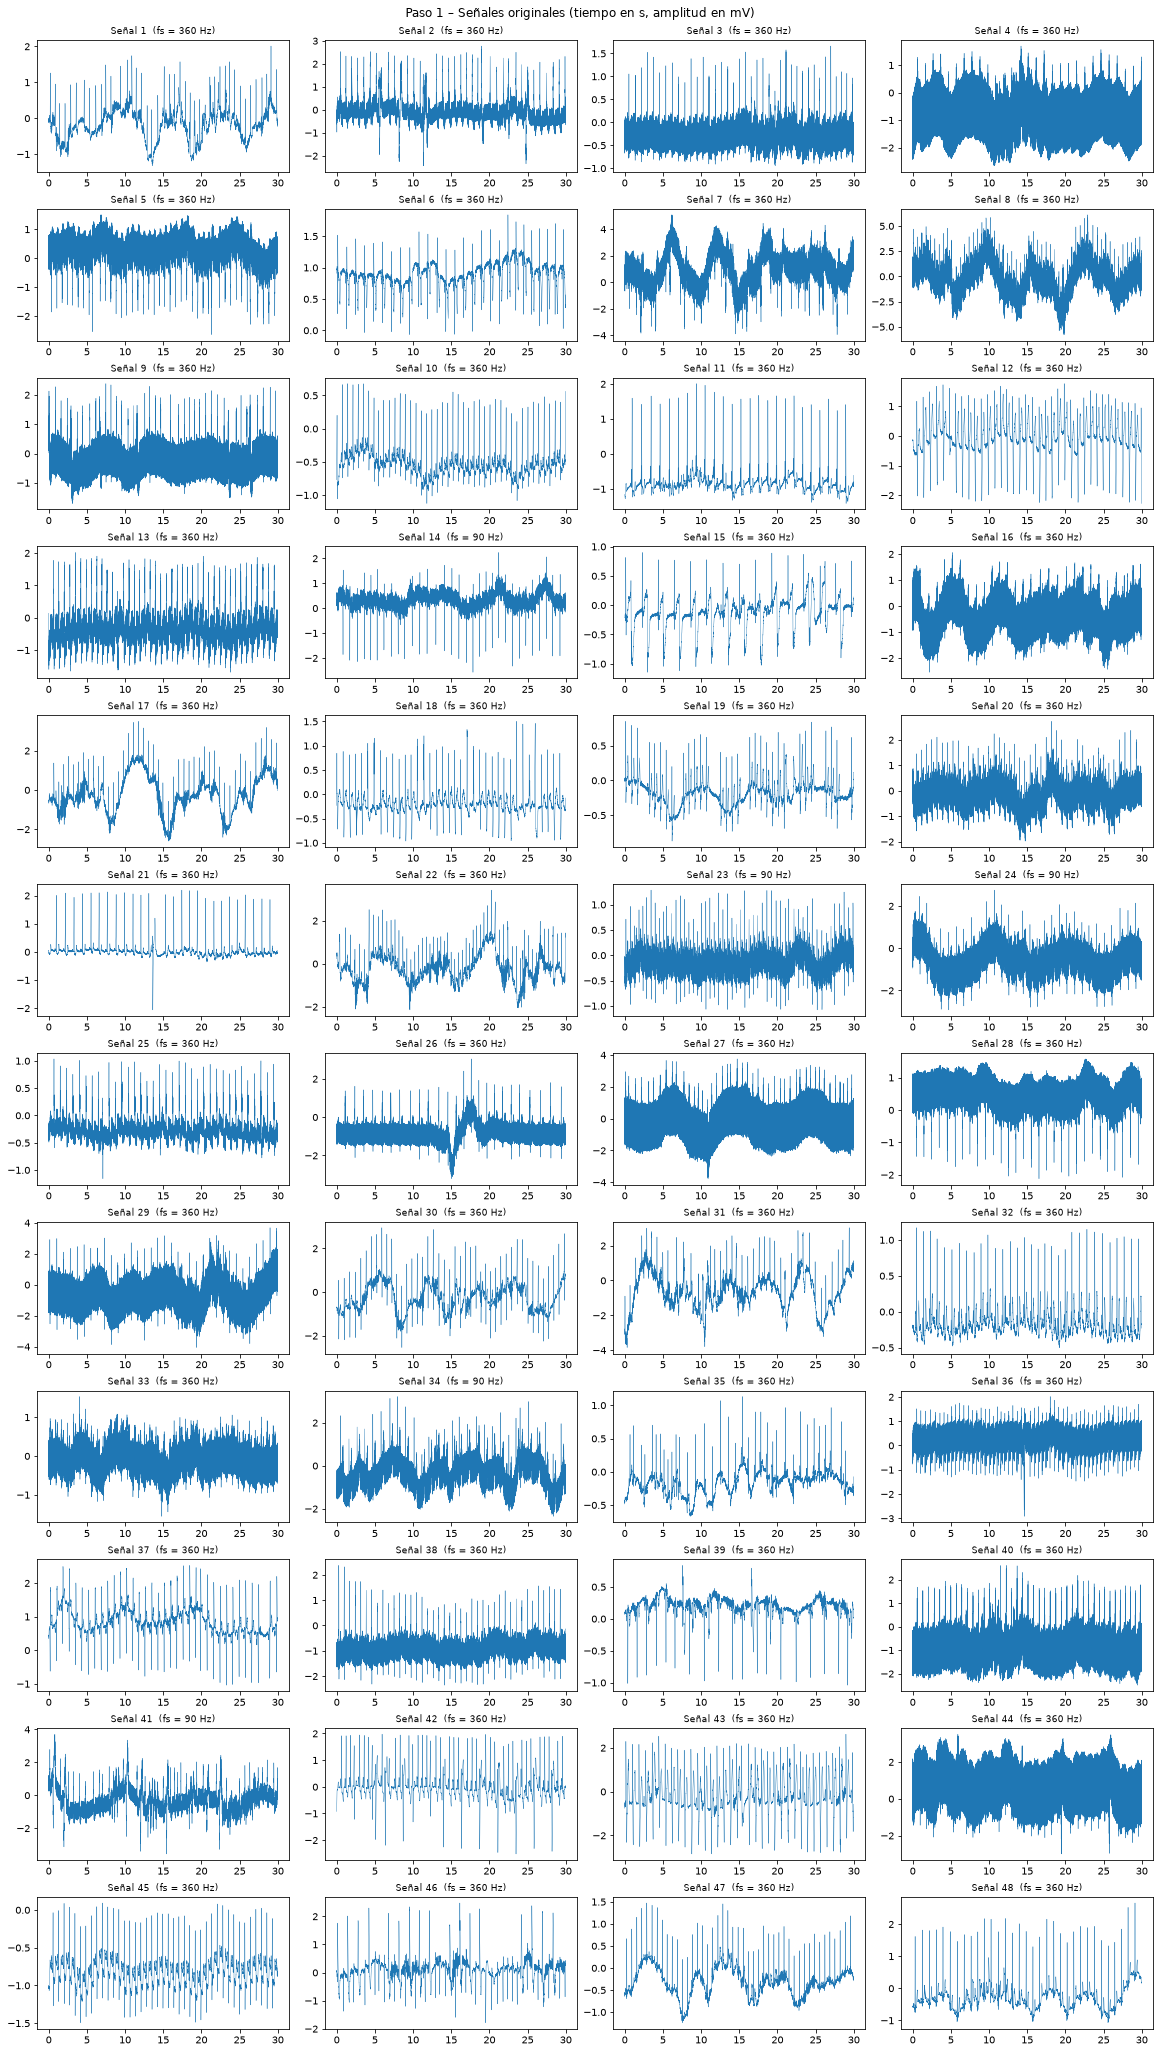

In [12]:
S = {}
for n in SENALES:
    t, x, fs = leer_senal(n)
    S[n] = {"t": t, "x": x, "fs": fs}

fig, ejes = cuadricula(len(SENALES))
for k, n in enumerate(SENALES):
    ejes[k].plot(S[n]["t"], S[n]["x"], linewidth=0.4)
    ejes[k].set_title("Señal " + str(n) + "  (fs = " + str(S[n]["fs"]) + " Hz)", fontsize=9)
fig.suptitle("Paso 1 – Señales originales (tiempo en s, amplitud en mV)")
plt.show()

## **Paso 2 – Revisar el LEEME y clasificar por frecuencia**
**Hace:** comparo la $f_s$ calculada con la del LEEME y clasifico cada señal en grupo A o B.

**Muestra:** una tabla con la $f_s$ del LEEME, la calculada, el grupo y dónde va el notch.

In [13]:
fs_leeme = leer_leeme()
tabla = []
for n in SENALES:
    grupo, notch = clasificar(S[n]["fs"])
    S[n]["grupo"] = grupo
    S[n]["notch"] = notch
    if fs_leeme.get(n) == S[n]["fs"]:
        coincide = "sí"
    else:
        coincide = "NO"          # o no coincide, o la señal no está en el LEEME (archivo nuevo)
    tabla.append([n, fs_leeme.get(n, "no está"), S[n]["fs"], coincide, S[n]["fs"] / 2, grupo, notch])

tabla = pd.DataFrame(tabla, columns=["senal", "fs_LEEME", "fs_calculada", "coincide", "Nyquist", "grupo", "notch_Hz"])
print(tabla.to_string(index=False))
print("\nSeñales del grupo A (la red cabe):", list(tabla[tabla.grupo == "A"].senal))
print("Señales del grupo B (aliasing):   ", list(tabla[tabla.grupo == "B"].senal))

 senal  fs_LEEME  fs_calculada coincide  Nyquist grupo  notch_Hz
     1     360.0           360       sí    180.0     A [60, 120]
     2     360.0           360       sí    180.0     A [60, 120]
     3     360.0           360       sí    180.0     A [60, 120]
     4     360.0           360       sí    180.0     A [60, 120]
     5     360.0           360       sí    180.0     A [60, 120]
     6     360.0           360       sí    180.0     A [60, 120]
     7     360.0           360       sí    180.0     A [60, 120]
     8     360.0           360       sí    180.0     A [60, 120]
     9     360.0           360       sí    180.0     A [60, 120]
    10     360.0           360       sí    180.0     A [60, 120]
    11     360.0           360       sí    180.0     A [60, 120]
    12     360.0           360       sí    180.0     A [60, 120]
    13     360.0           360       sí    180.0     A [60, 120]
    14      90.0            90       sí     45.0     B      [30]
    15     360.0         

## **Paso 3 – Espectro y filtro notch**
**Hace:** calculo el espectro, aplico el notch y vuelvo a calcular el espectro.

**Muestra:** el espectro antes (gris) y después del notch (azul). La línea naranja es donde está la red: 60 Hz en el grupo A, la frecuencia alias en el grupo B (30 Hz con $f_s$ = 90 Hz). El pico debe desaparecer.

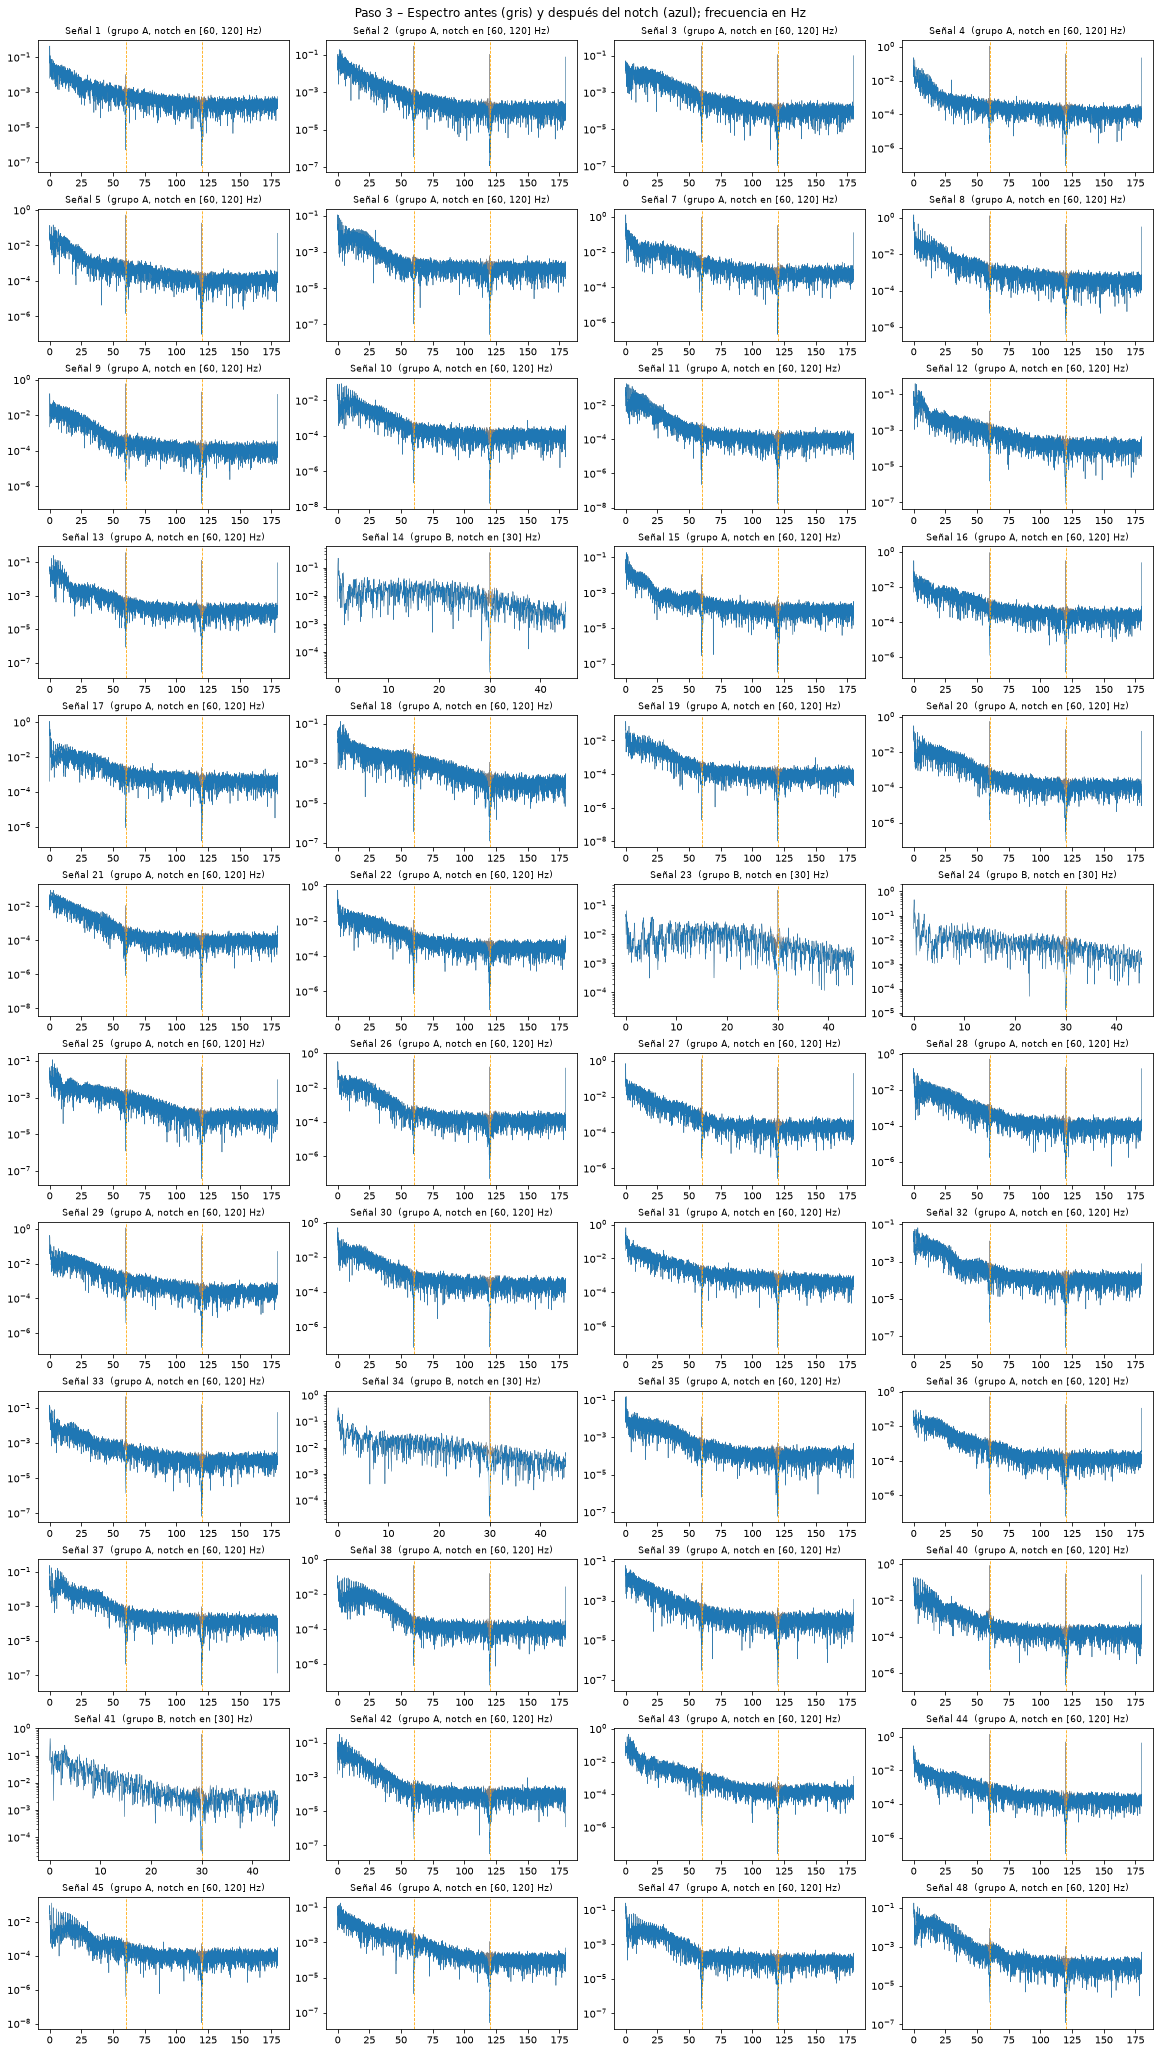

In [14]:
for n in SENALES:
    S[n]["x_notch"] = filtro_notch(S[n]["x"], S[n]["fs"], S[n]["notch"])

fig, ejes = cuadricula(len(SENALES))
for k, n in enumerate(SENALES):
    f, antes = espectro(S[n]["x"], S[n]["fs"])
    f, despues = espectro(S[n]["x_notch"], S[n]["fs"])
    ejes[k].semilogy(f, antes, linewidth=0.4, color="gray")
    ejes[k].semilogy(f, despues, linewidth=0.4, color="tab:blue")
    for f0 in S[n]["notch"]:
        ejes[k].axvline(f0, color="orange", linestyle="--", linewidth=0.8)
    ejes[k].set_title("Señal " + str(n) + "  (grupo " + S[n]["grupo"] + ", notch en " + str(S[n]["notch"]) + " Hz)", fontsize=9)
fig.suptitle("Paso 3 – Espectro antes (gris) y después del notch (azul); frecuencia en Hz")
plt.show()

## **Paso 4 – Filtro pasa-banda 5–15 Hz**
**Muestra:** de 5 a 10 s, la señal original (gris) y la filtrada (azul). La filtrada queda sin deriva y con los QRS resaltados.

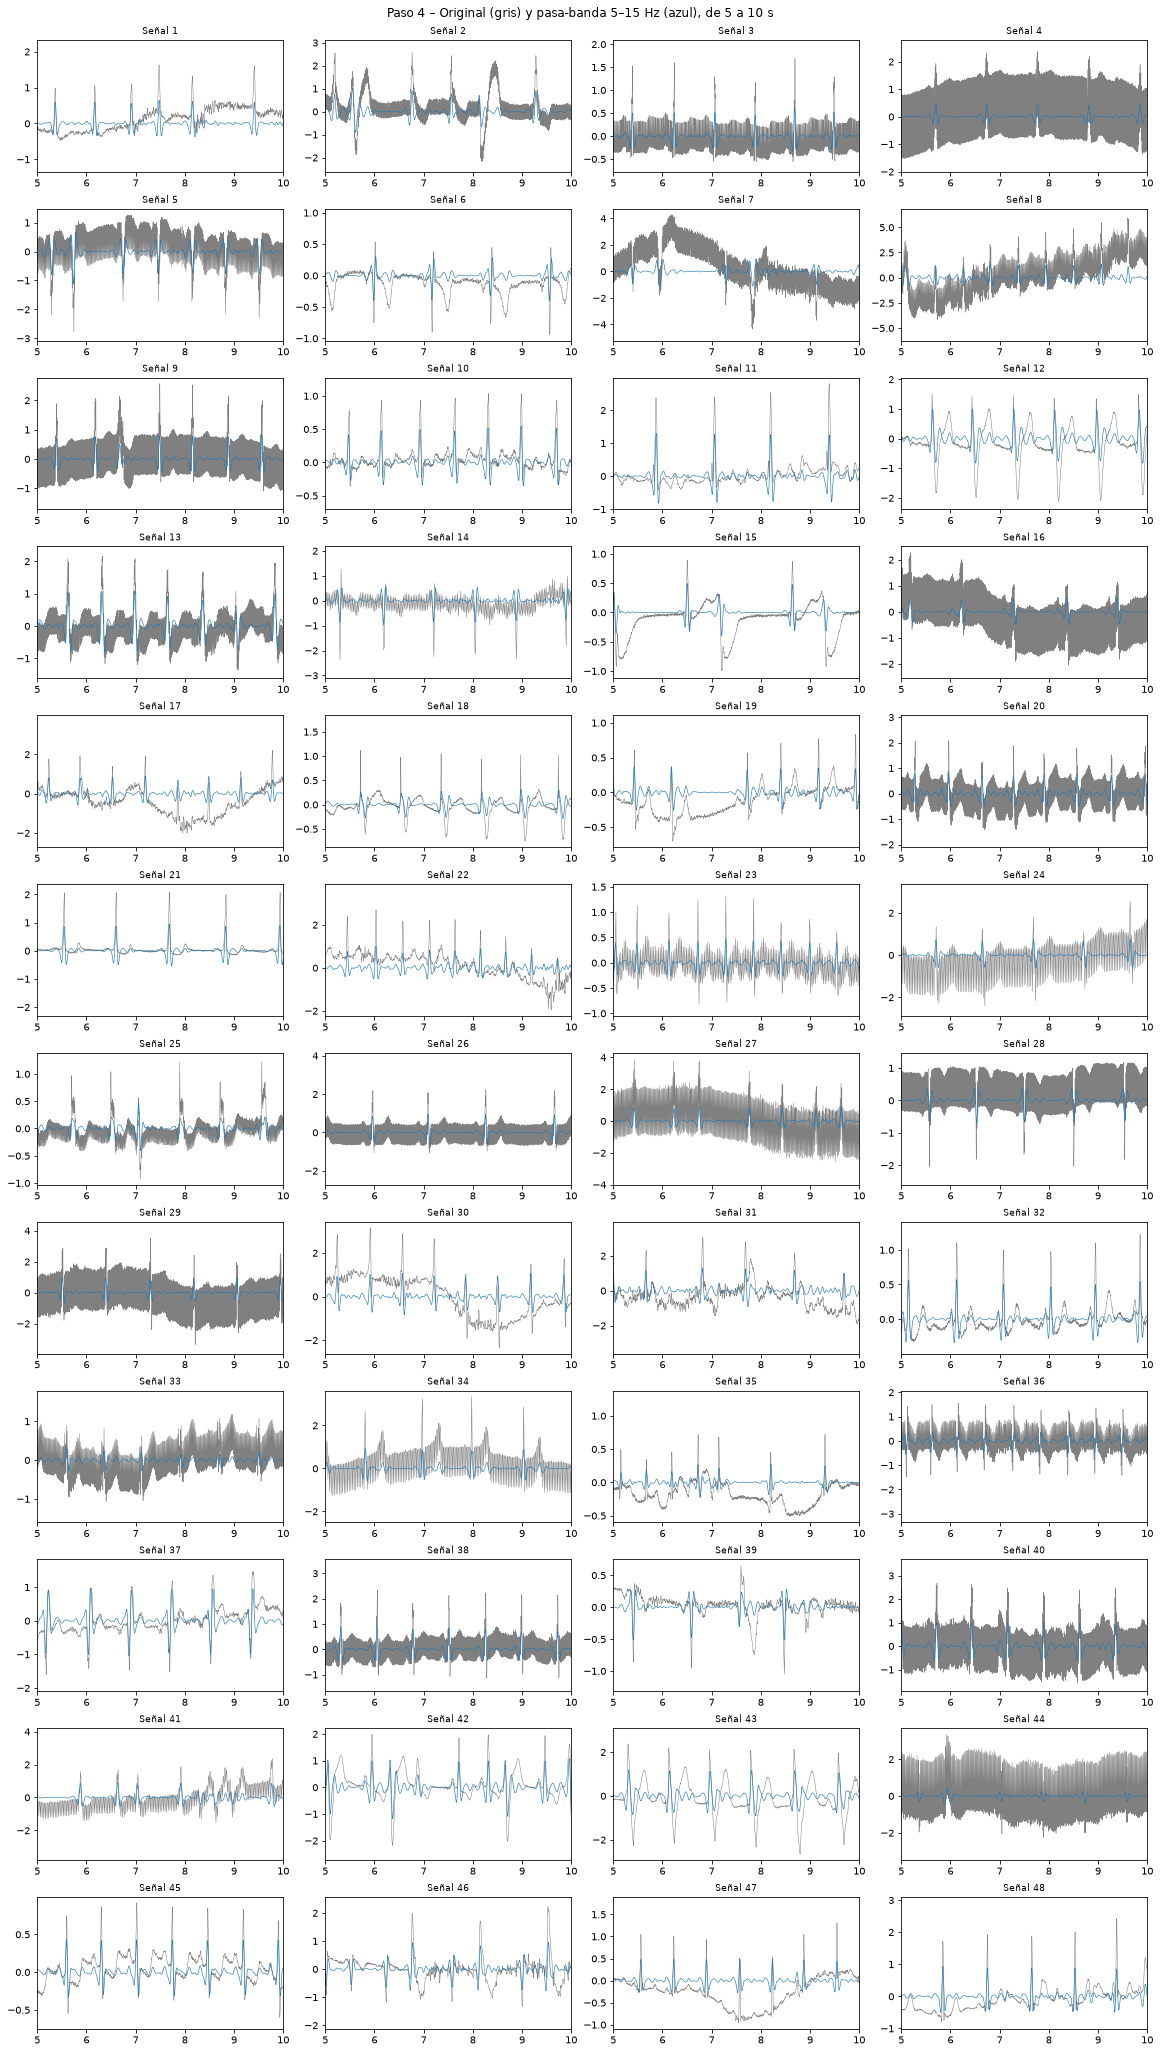

In [15]:
for n in SENALES:
    S[n]["x_banda"] = filtro_pasa_banda(S[n]["x_notch"], S[n]["fs"])

fig, ejes = cuadricula(len(SENALES))
for k, n in enumerate(SENALES):
    ejes[k].plot(S[n]["t"], S[n]["x"] - np.mean(S[n]["x"]), linewidth=0.5, color="gray")
    ejes[k].plot(S[n]["t"], S[n]["x_banda"], linewidth=0.6, color="tab:blue")
    ejes[k].set_xlim(5, 10)
    ejes[k].set_title("Señal " + str(n), fontsize=9)
fig.suptitle("Paso 4 – Original (gris) y pasa-banda 5–15 Hz (azul), de 5 a 10 s")
plt.show()

## **Paso 5 – Transformación de Pan y Tompkins**
**Muestra:** la señal integrada. Cada joroba es un latido.

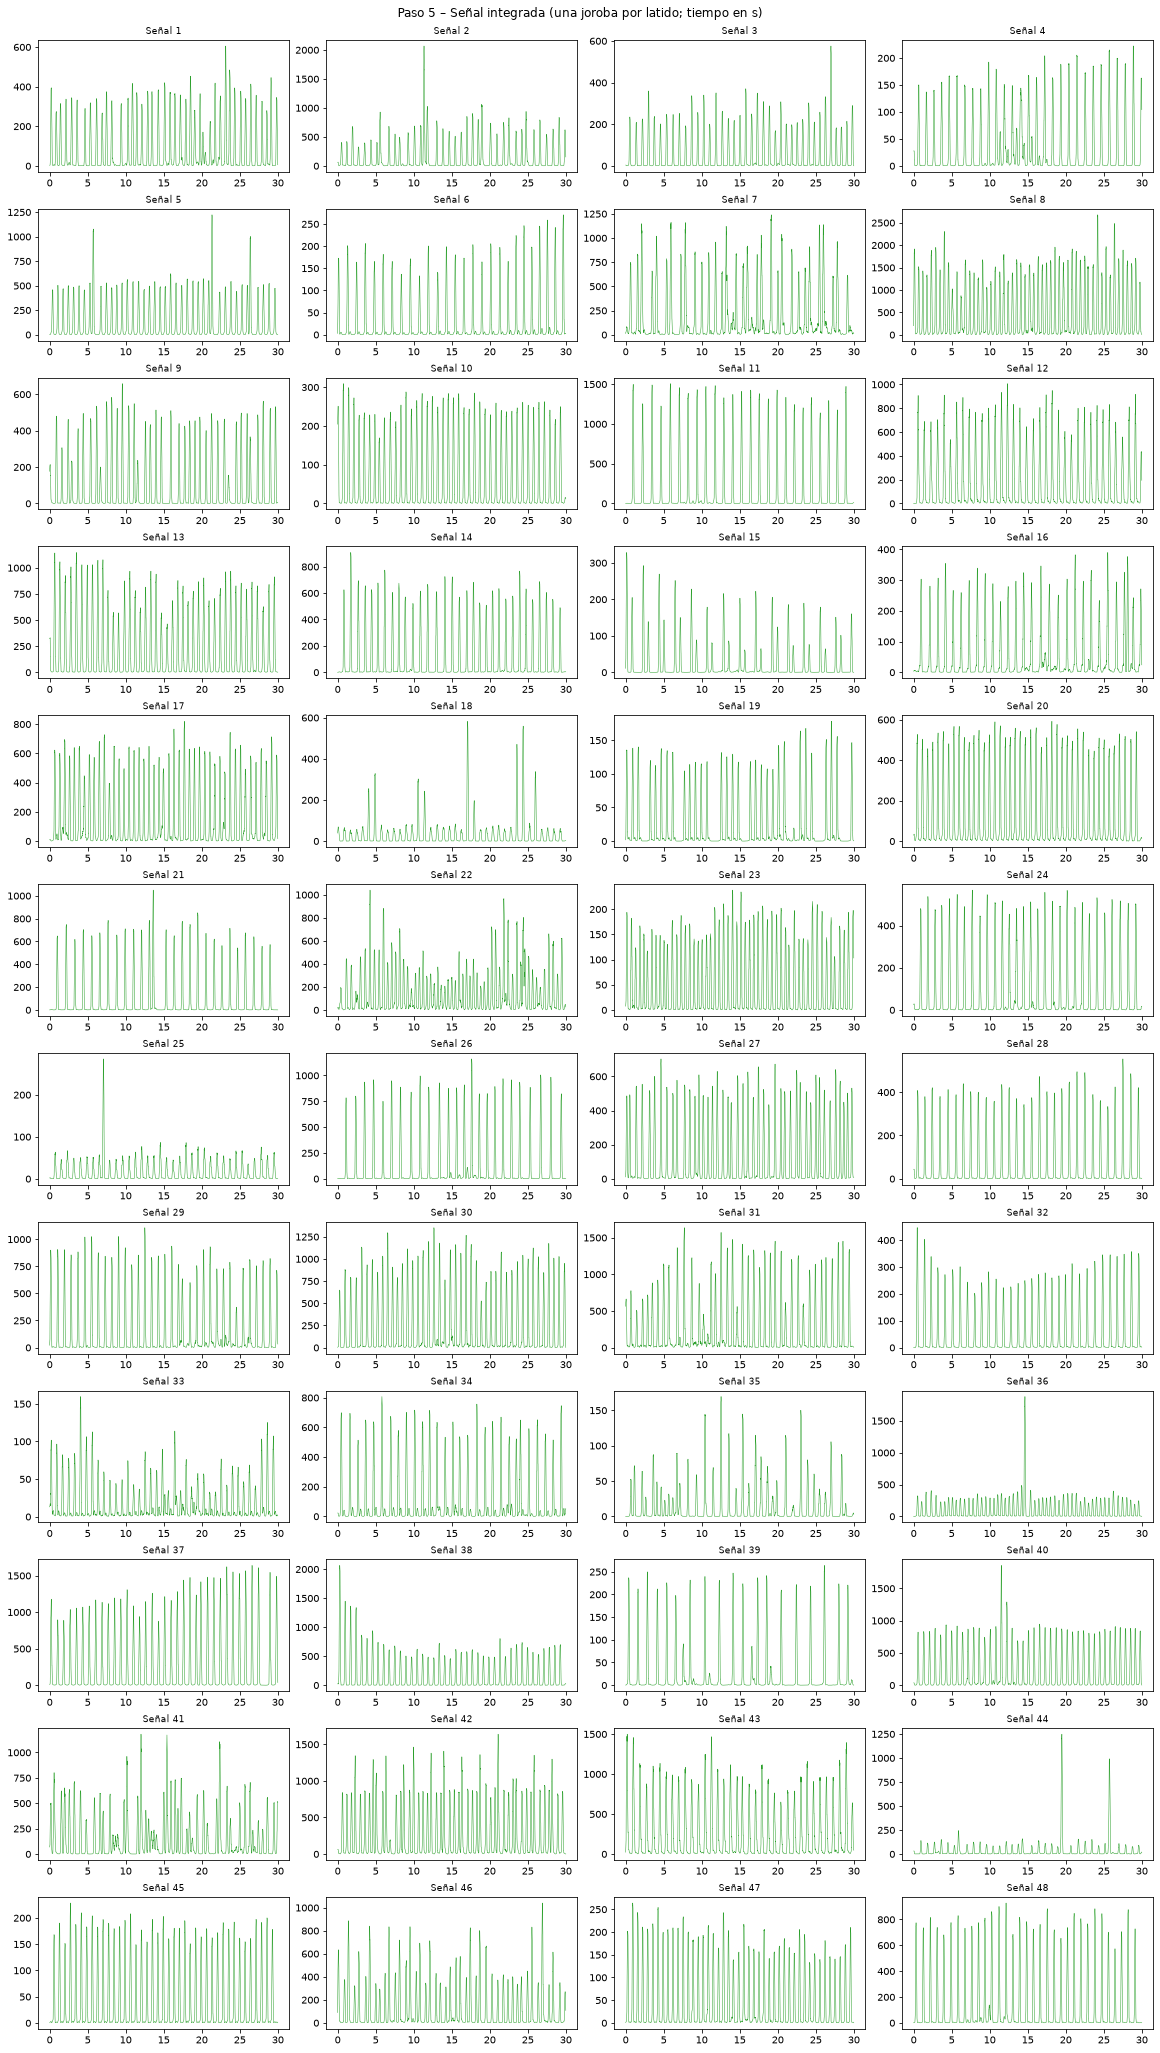

In [16]:
for n in SENALES:
    S[n]["integrada"] = pan_tompkins(S[n]["x_banda"], S[n]["fs"])

fig, ejes = cuadricula(len(SENALES))
for k, n in enumerate(SENALES):
    ejes[k].plot(S[n]["t"], S[n]["integrada"], linewidth=0.5, color="tab:green")
    ejes[k].set_title("Señal " + str(n), fontsize=9)
fig.suptitle("Paso 5 – Señal integrada (una joroba por latido; tiempo en s)")
plt.show()

## **Paso 6 – Picos R**
**Hace:** `detectar_picos` → `depurar_picos` → `ubicar_pico_r`.

**Muestra:** la señal filtrada con los picos R en rojo y el número de latidos en el título.

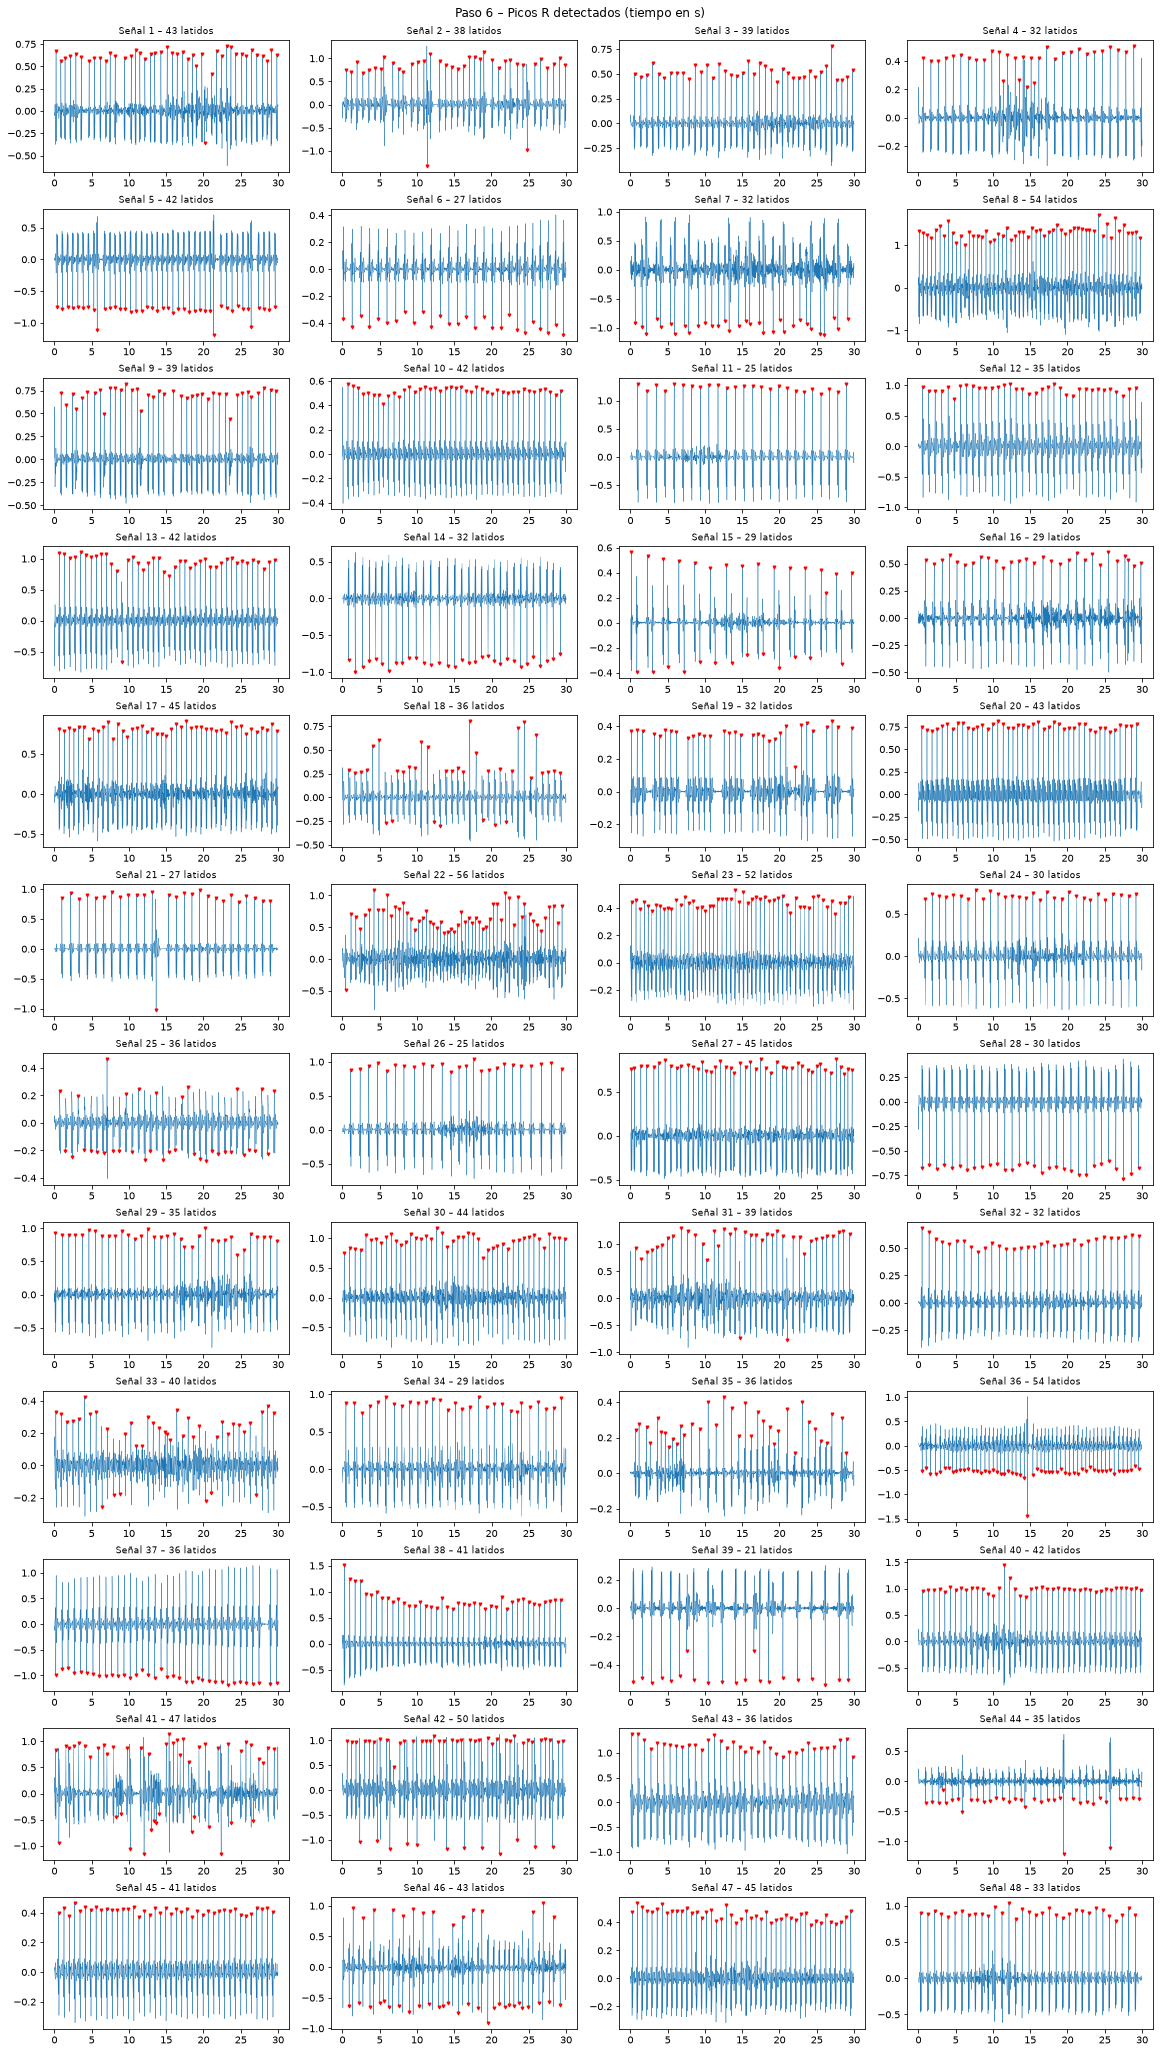

In [17]:
for n in SENALES:
    fs = S[n]["fs"]
    picos = detectar_picos(S[n]["integrada"], fs)
    picos = depurar_picos(picos, S[n]["integrada"], fs)
    S[n]["picos"] = ubicar_pico_r(picos, S[n]["x_banda"], fs)

fig, ejes = cuadricula(len(SENALES))
for k, n in enumerate(SENALES):
    p = S[n]["picos"]
    ejes[k].plot(S[n]["t"], S[n]["x_banda"], linewidth=0.4)
    ejes[k].plot(S[n]["t"][p], S[n]["x_banda"][p], "rv", markersize=3)
    ejes[k].set_title("Señal " + str(n) + " – " + str(len(p)) + " latidos", fontsize=9)
fig.suptitle("Paso 6 – Picos R detectados (tiempo en s)")
plt.show()

## **Paso 7 – Intervalos RR y frecuencia cardiaca**
**Muestra:** el tacograma de cada señal (cada RR en el tiempo; la línea punteada es el promedio) y la tabla final con la FC.

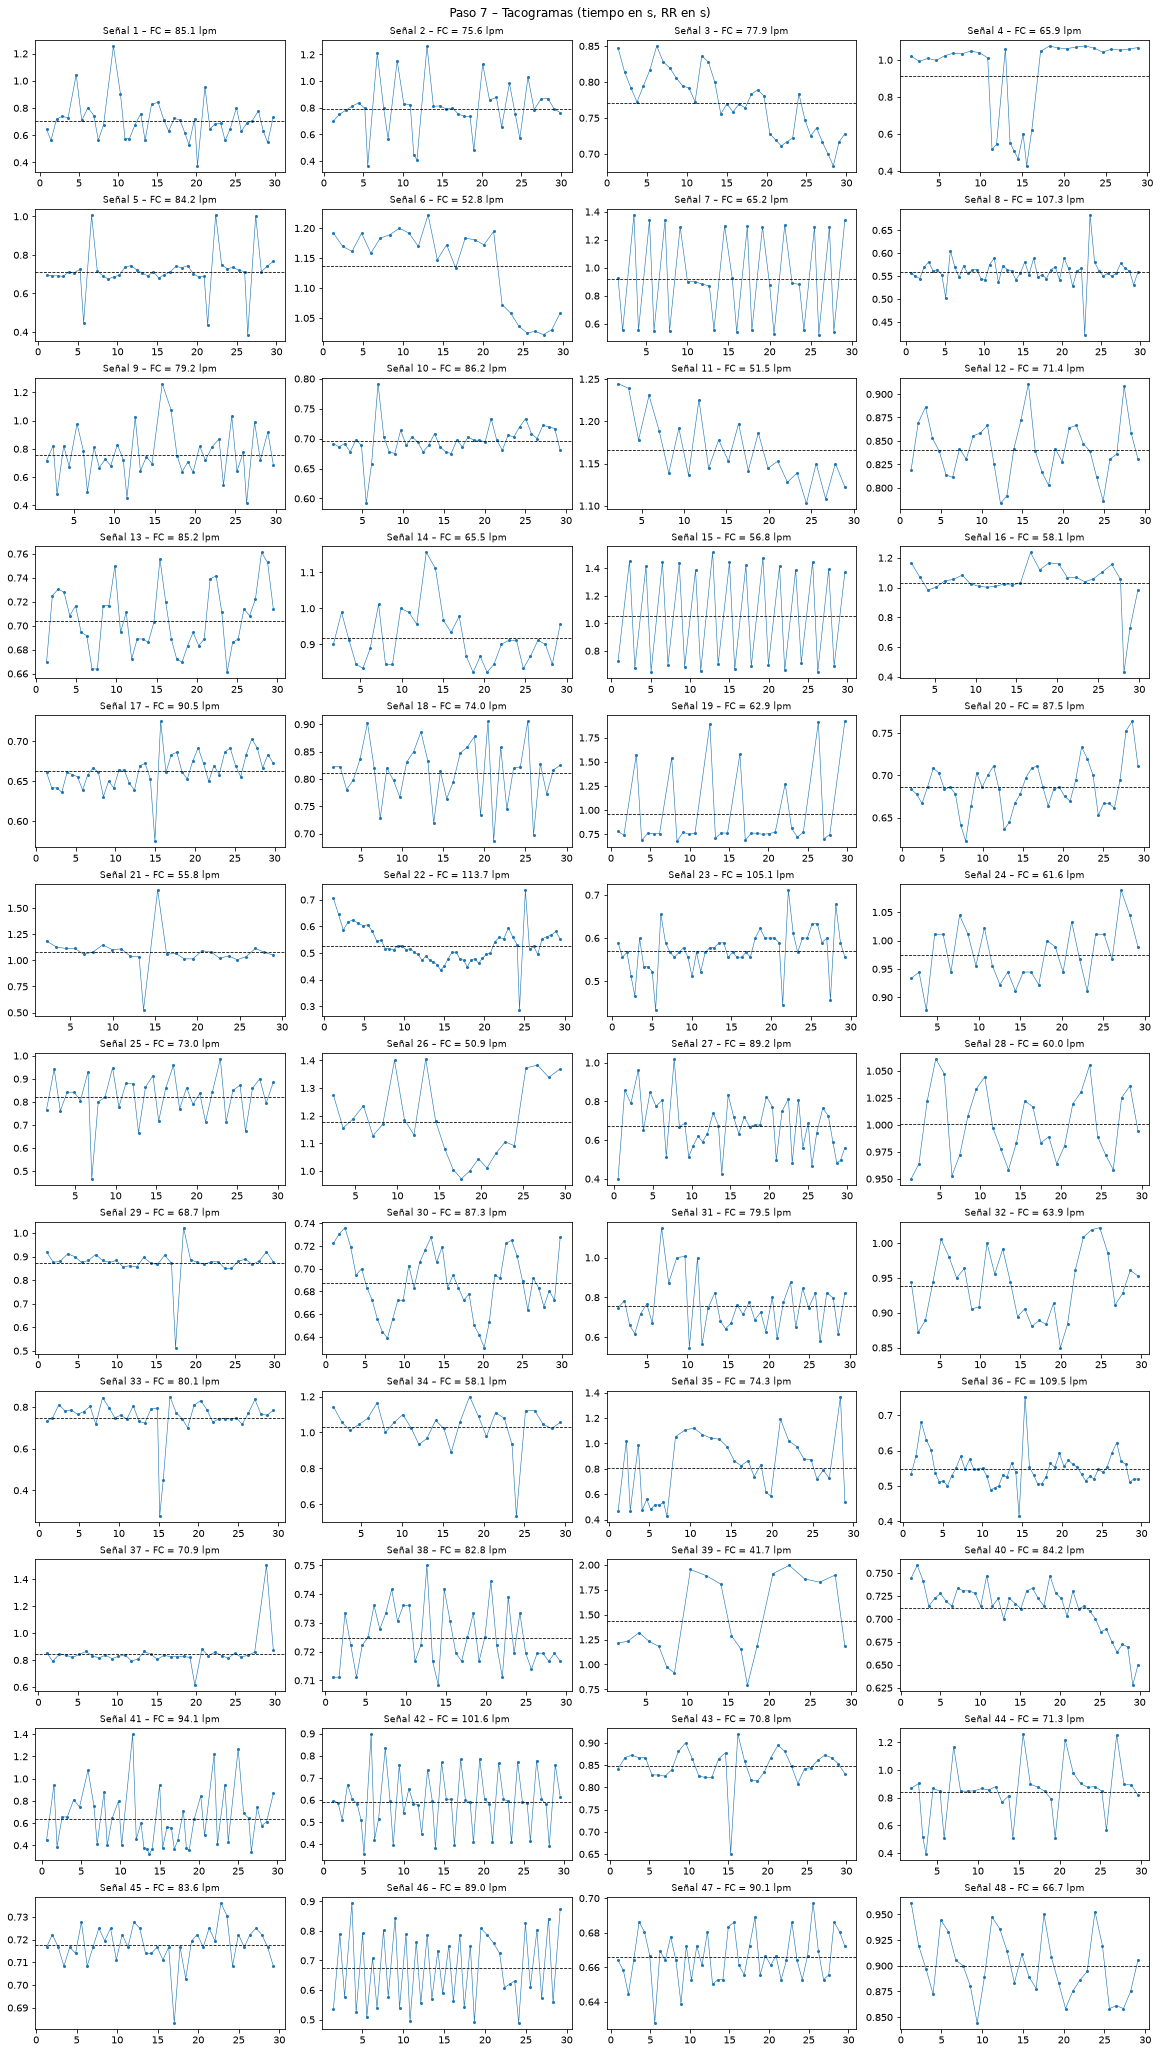

 senal  fs_Hz  latidos  RR_promedio_s  FC_lpm
     1    360       43          0.705   85.06
     2    360       38          0.794   75.55
     3    360       39          0.770   77.91
     4    360       32          0.911   65.87
     5    360       42          0.713   84.17
     6    360       27          1.136   52.81
     7    360       32          0.920   65.21
     8    360       54          0.559  107.27
     9    360       39          0.758   79.20
    10    360       42          0.696   86.20
    11    360       25          1.165   51.48
    12    360       35          0.840   71.39
    13    360       42          0.704   85.19
    14     90       32          0.916   65.47
    15    360       29          1.055   56.85
    16    360       29          1.032   58.15
    17    360       45          0.663   90.49
    18    360       36          0.811   73.99
    19    360       32          0.954   62.89
    20    360       43          0.686   87.48
    21    360       27          1.

In [18]:
resultado = []
for n in SENALES:
    rr, fc = calcular_fc(S[n]["picos"], S[n]["fs"])
    S[n]["rr"] = rr
    S[n]["fc"] = fc
    resultado.append([n, S[n]["fs"], len(S[n]["picos"]), round(np.mean(rr), 3), round(fc, 2)])

fig, ejes = cuadricula(len(SENALES))
for k, n in enumerate(SENALES):
    p = S[n]["picos"]
    ejes[k].plot(S[n]["t"][p[1:]], S[n]["rr"], "o-", markersize=2, linewidth=0.6)
    ejes[k].axhline(np.mean(S[n]["rr"]), color="k", linestyle="--", linewidth=0.8)
    ejes[k].set_title("Señal " + str(n) + " – FC = " + str(round(S[n]["fc"], 1)) + " lpm", fontsize=9)
fig.suptitle("Paso 7 – Tacogramas (tiempo en s, RR en s)")
plt.show()

resultado = pd.DataFrame(resultado, columns=["senal", "fs_Hz", "latidos", "RR_promedio_s", "FC_lpm"])
print(resultado.to_string(index=False))

# **PARTE D – Archivo de resultados de las 48 señales**
**Hace:** repito los Pasos 1 a 7 (sin gráficas) para las 48 señales, sin importar qué haya en `SENALES`, y guardo `resultados_g08.csv` con las columnas `senal` y `FC_lpm`.

In [19]:
nombres = []
fcs = []
for n in range(1, 49):
    t, x, fs = leer_senal(n)
    grupo, notch = clasificar(fs)
    x_banda = filtro_pasa_banda(filtro_notch(x, fs, notch), fs)
    integrada = pan_tompkins(x_banda, fs)
    picos = depurar_picos(detectar_picos(integrada, fs), integrada, fs)
    picos = ubicar_pico_r(picos, x_banda, fs)
    rr, fc = calcular_fc(picos, fs)
    nombres.append("senal_" + str(n).zfill(2))
    fcs.append(round(fc, 2))

archivo = pd.DataFrame({"senal": nombres, "FC_lpm": fcs})
archivo.to_csv("resultados_g08.csv", index=False)
print("Guardé resultados_g08.csv")
print(archivo.to_string(index=False))

Guardé resultados_g08.csv
   senal  FC_lpm
senal_01   85.06
senal_02   75.55
senal_03   77.91
senal_04   65.87
senal_05   84.17
senal_06   52.81
senal_07   65.21
senal_08  107.27
senal_09   79.20
senal_10   86.20
senal_11   51.48
senal_12   71.39
senal_13   85.19
senal_14   65.47
senal_15   56.85
senal_16   58.15
senal_17   90.49
senal_18   73.99
senal_19   62.89
senal_20   87.48
senal_21   55.78
senal_22  113.75
senal_23  105.11
senal_24   61.58
senal_25   72.97
senal_26   50.89
senal_27   89.20
senal_28   59.98
senal_29   68.65
senal_30   87.27
senal_31   79.47
senal_32   63.91
senal_33   80.13
senal_34   58.13
senal_35   74.34
senal_36  109.46
senal_37   70.87
senal_38   82.77
senal_39   41.67
senal_40   84.22
senal_41   94.13
senal_42  101.60
senal_43   70.83
senal_44   71.27
senal_45   83.61
senal_46   89.03
senal_47   90.11
senal_48   66.69


## **Referencias**
1. **Pan, J. y Tompkins, W. J.** (1985). A real-time QRS detection algorithm. *IEEE Transactions on Biomedical Engineering*, BME-32(3), 230–236. DOI: [10.1109/TBME.1985.325532](https://doi.org/10.1109/TBME.1985.325532). Pasa-banda 5–15 Hz: *Bandpass Filter*, p. 232; derivada: *Derivative*, pp. 232–233; cuadrado e integración: p. 233; umbrales: *Adjusting the Thresholds*, pp. 233–234; refractario de 200 ms: *Algorithm Overview*, p. 231; búsqueda del 166 %: p. 234.
2. **Oppenheim, A. V. y Schafer, R. W.** (2010). *Discrete-Time Signal Processing* (3.ª ed.). Pearson. Sec. 4.1 (muestreo), Sec. 4.2 (Nyquist y aliasing), Cap. 7 (Butterworth), Cap. 8–9 (DFT y FFT).
3. **Proakis, J. G. y Manolakis, D. G.** (2007). *Digital Signal Processing: Principles, Algorithms, and Applications* (4.ª ed.). Pearson. Sec. 1.4 (frecuencia alias), Sec. 5.4 (filtros notch).
4. **Kligfield, P. et al.** (2007). Recommendations for the standardization and interpretation of the electrocardiogram. Part I. *Circulation*, 115(10), 1306–1324. DOI: [10.1161/CIRCULATIONAHA.106.180200](https://doi.org/10.1161/CIRCULATIONAHA.106.180200). Frecuencia de muestreo recomendada para el ECG.